# Anomalib 사용법 입문 · PatchCore

정상 이미지로 **PatchCore**를 학습하고, 새로운 이미지의 이상 여부와 위치를 찾아보자.

이 노트북은 **실행 환경과 데이터가 없는 Windows PC**에서 시작한다. Python 설치부터 데이터 다운로드, 학습, 평가, 추론, 모델 저장까지 순서대로 진행한다. 학습에 필요한 코드는 노트북 안에 있으며, 별도 프로젝트 파일을 가져올 필요가 없다.

| 실습 | 데이터 | 배우는 API |
|---|---|---|
| 공개 데이터 실습 | MVTec AD의 `bottle` | `MVTecAD`로 표준 데이터 읽기 |
| 사용자 데이터 실습 | `hazelnut_toy` | `Folder`로 내 이미지 폴더 연결하기 |

두 실습 모두 `데이터 → PatchCore → Engine.fit/test/predict`라는 같은 흐름을 사용한다.


## 실행 준비 · 처음 한 번

### Python과 Jupyter 설치

1. [Python 3.11 Windows 설치 파일](https://www.python.org/downloads/release/python-3119/)로 Python을 설치한다. 설치할 때 **Python Launcher**를 포함한다.
2. PowerShell을 열고 아래 명령을 순서대로 실행한다. 영문 경로인 `C:\anomalib_lab`을 사용한다.

```powershell
mkdir C:\anomalib_lab
cd C:\anomalib_lab
py -3.11 -m venv .venv
.\.venv\Scripts\python -m pip install --upgrade pip
.\.venv\Scripts\python -m pip install torch==2.5.1 torchvision==0.20.1 --index-url https://download.pytorch.org/whl/cu121
.\.venv\Scripts\python -m pip install anomalib==2.2.0 lightning==2.5.5 pytorch-lightning==2.5.5 torchmetrics==1.8.2 timm==1.0.20 huggingface_hub==0.34.4 pandas==2.2.3 scikit-learn==1.6.1 jupyterlab ipywidgets
.\.venv\Scripts\python -m jupyter lab
```

위 PyTorch 명령은 **NVIDIA GPU가 있는 Windows PC**용이다. GPU가 없으면 해당 명령의 URL 끝 `cu121`을 `cpu`로 바꾼다. CUDA Toolkit을 별도로 설치할 필요는 없으며, GPU를 사용하려면 호환되는 NVIDIA 드라이버가 있어야 한다.

Jupyter가 열리면 이 노트북을 업로드하고 **Python 3 (ipykernel)** 커널을 선택한다. 방금 만든 가상환경의 Jupyter에서 열어야 한다. VS Code에서는 `C:\anomalib_lab\.venv\Scripts\python.exe`를 커널로 선택한다. 설치 후에는 커널을 재시작하고 아래 셀부터 실행한다.

### 실습에 필요한 다운로드

최초 실행에는 인터넷이 필요하다. PyTorch와 패키지 설치에 수 GB의 공간이 필요하며, 아래에서 MVTec AD의 bottle 범주, 약 6.4MB의 hazelnut_toy, ResNet18 사전학습 가중치를 내려받는다. 이미 받은 데이터는 재사용한다. 실습 결과는 `C:/anomalib_lab/results/patchcore_usage`에 저장한다.


> **[참고] 실습 PC(RTX 5070 등 최신 GPU) 환경 안내**:
> 최신 NVIDIA Blackwell 아키텍처(RTX 50-시리즈)는 PyTorch 2.5.1+cu121에서 sm_120 커널 미지원 오류가 발생할 수 있습니다. 본 노트북은 해당 GPU를 정상 지원하는 **CUDA 12.8 지원 Conda 환경(`cuda_env` / Python 3.10)**을 커널로 선택하여 모든 실습(학습·평가·추론·시각화)을 정상 수행하였습니다. (상세 내용은 노트북 최하단 참고)


In [1]:
from pathlib import Path
from importlib.metadata import version

import torch
import pandas as pd
from lightning.pytorch import seed_everything
from huggingface_hub import snapshot_download
from anomalib.data import MVTecAD, Folder
from anomalib.data.utils import DownloadInfo, download_and_extract
from anomalib.engine import Engine
from anomalib.models import Patchcore
from anomalib.visualization import visualize_image_item
from IPython.display import display

DATA = Path('C:/anomalib_lab/datasets')
RESULTS = Path('C:/anomalib_lab/results/patchcore_usage')
DATA.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
seed_everything(42)

print('Anomalib:', version('anomalib'), '/ PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU 사용')


Anomalib: 2.2.0 / PyTorch: 2.12.0.dev20260408+cu128
GPU: NVIDIA GeForce RTX 5070 Laptop GPU


### Windows에서 결과 폴더 만들기

Anomalib 2.2.0은 결과 폴더에 심볼릭 링크를 만들려고 한다. 아래의 짧은 `NotebookEngine`은 이를 일반 폴더로 바꿔 관리자 권한 없이 실행하게 한다. 학습·평가·추론은 Anomalib의 `Engine` 기능을 그대로 사용한다. 이 셀은 한 번 실행하고 이후에는 `fit`, `test`, `predict`의 사용법에 집중한다.


In [2]:
class NotebookEngine(Engine):
    def _setup_workspace(self, *args, **kwargs):
        kwargs['versioned_dir'] = False
        return super()._setup_workspace(*args, **kwargs)


## 1. MVTec AD 데이터 내려받기

MVTec AD는 정상 제품과 여러 결함의 이미지·정답 마스크를 제공한다. 여기서는 병의 파손과 오염을 검사하는 **bottle** 범주만 사용한다.

설치 버전의 기본 다운로드 주소가 동작하지 않아, 아래에서는 고정 버전의 [공개 미러](https://huggingface.co/datasets/foersben/mvtec-ad/tree/28afa1599de4e2214db952d6f5475138934d084c/bottle)에서 bottle 폴더를 받는다. 이 미러는 MVTec의 공식 배포처와 구분하며, 원본 MVTec AD의 **CC BY-NC-SA 4.0** 조건을 따른다.

`snapshot_download`는 저장소의 파일을 폴더로 내려받는다. `allow_patterns='bottle/**'`는 필요한 범주만 선택하고, `revision`은 같은 자료를 받도록 버전을 고정한다.


In [3]:
snapshot_download(
    repo_id='foersben/mvtec-ad',
    repo_type='dataset',
    revision='28afa1599de4e2214db952d6f5475138934d084c',
    allow_patterns='bottle/**',
    local_dir=DATA / 'MVTecAD',
)
print('준비된 폴더:', DATA / 'MVTecAD/bottle')



Fetching 357 files:   0%|          | 0/357 [00:00<?, ?it/s]


Fetching 357 files:  15%|█▍        | 53/357 [00:00<00:00, 523.80it/s]


Fetching 357 files:  31%|███       | 110/357 [00:00<00:00, 517.99it/s]


Fetching 357 files:  45%|████▌     | 162/357 [00:00<00:00, 410.99it/s]


Fetching 357 files:  58%|█████▊    | 206/357 [00:00<00:00, 400.01it/s]


Fetching 357 files:  71%|███████▏  | 255/357 [00:00<00:00, 424.43it/s]


Fetching 357 files:  88%|████████▊ | 313/357 [00:00<00:00, 468.55it/s]


Fetching 357 files: 100%|██████████| 357/357 [00:00<00:00, 468.13it/s]

준비된 폴더: C:\anomalib_lab\datasets\MVTecAD\bottle


## 2. MVTecAD로 학습·검증·시험 데이터 읽기

데이터는 다음 구조를 가진다. `root`에는 `bottle`의 **상위 폴더**를 지정한다.

```text
datasets/MVTecAD/bottle/
├── train/good/                 정상 학습 이미지
├── test/good/                  정상 평가 이미지
├── test/broken_large/          큰 파손
├── test/broken_small/          작은 파손
├── test/contamination/         오염
└── ground_truth/<결함 종류>/    이상 영역 정답 마스크
```

`MVTecAD`는 이 구조를 알고 있으므로 이미지와 마스크를 직접 연결할 필요가 없다. `val_split_mode='from_test'`는 공식 test를 검증과 시험으로 나눈다. 검증 데이터는 임계값을 정할 때, 시험 데이터는 성능을 측정할 때 사용한다. 정상 학습 데이터는 그대로 유지한다.

`seed=42`는 분할의 난수 출발점을 고정하고, `num_workers=0`은 Windows Jupyter에서 데이터 읽기를 단순하게 한다. batch size는 한 번에 처리할 이미지 수다. 이번 분할은 수업용이며 공식 test 전체를 평가하는 벤치마크와 구분한다.


In [4]:
mvtec_data = MVTecAD(
    root=DATA / 'MVTecAD',
    category='bottle',
    train_batch_size=4,
    eval_batch_size=4,
    num_workers=0,
    val_split_mode='from_test',
    val_split_ratio=0.5,
    seed=42,
)
mvtec_data.setup()

pd.Series({
    '정상 학습 이미지': len(mvtec_data.train_data),
    '검증 이미지': len(mvtec_data.val_data),
    '시험 이미지': len(mvtec_data.test_data),
}, name='MVTec AD 영상 수')


정상 학습 이미지    209
검증 이미지        41
시험 이미지        42
Name: MVTec AD 영상 수, dtype: int64

## 3. PatchCore 생성하고 학습하기

PatchCore는 사전학습 CNN에서 정상 이미지의 **작은 영역별 특징**을 추출해 메모리 뱅크에 저장한다. 새로운 이미지의 특징이 저장된 정상 특징과 멀수록 이상 점수가 커진다.

- `backbone='resnet18'`: 특징을 추출할 CNN. 노트북 PC의 메모리 사용량을 줄인다.
- `coreset_sampling_ratio=0.01`: 정상 특징 중 대표적인 1%를 메모리에 남긴다.
- `configure_pre_processor(image_size=(128,128))`: 입력 크기를 맞추고 ImageNet 정규화를 적용한다. 학습·추론에 같은 전처리를 사용한다.
- `visualizer=False`: 전체 시험 영상의 자동 저장을 생략하고, 뒤의 Anomalib 내장 시각화 함수로 선택한 예측을 표시한다.

`Engine.fit`이 정상 특징을 수집하고 검증 데이터의 결과로 점수 정규화와 판정 임계값을 정한다. 검증 라벨은 이 보정에 사용되므로, 이 예제는 **라벨이 있는 검증 데이터로 보정하는 파이프라인**이다. PatchCore는 역전파로 가중치를 반복 학습하는 모델이 아니며, 정상 특징을 한 번 수집한다. 학습 손실 곡선이 없어도 정상 동작이다.


In [5]:
mvtec_model = Patchcore(
    backbone='resnet18',
    coreset_sampling_ratio=0.01,
    pre_processor=Patchcore.configure_pre_processor(image_size=(128, 128)),
    visualizer=False,
)
mvtec_engine = NotebookEngine(default_root_dir=RESULTS / 'mvtecad')
mvtec_engine.fit(model=mvtec_model, datamodule=mvtec_data)


C:\Users\JIN\anaconda3\envs\cuda_env\lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


You are using a CUDA device ('NVIDIA GeForce RTX 5070 Laptop GPU') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


C:\Users\JIN\anaconda3\envs\cuda_env\lib\site-packages\lightning\pytorch\callbacks\model_checkpoint.py:881: Checkpoint directory C:\anomalib_lab\results\patchcore_usage\mvtecad\Patchcore\MVTecAD\bottle\latest\weights\lightning exists and is not empty.


... (79 outputs left out)


Epoch 0/0  --------------------------------- 53/53 0:00:10 • 0:00:00 5.68it/s 


Epoch 0/0  --------------------------------- 53/53 0:00:10 • 0:00:00 5.68it/s 

`Trainer.fit` stopped: `max_epochs=1` reached.



Epoch 0/0  --------------------------------- 53/53 0:00:10 • 0:00:00 5.68it/s 


## 4. test로 성능 확인하기

`test`는 시험 영상의 정답과 예측을 비교해 지표를 계산한다. 검증으로 정한 임계값은 유지한다.

| 지표 | 의미 |
|---|---|
| `image_AUROC` | 이미지 단위의 정상·이상 구분 능력 |
| `image_F1Score` | 현재 이미지 판정 임계값에서 정밀도와 재현율의 조화평균 |
| `pixel_AUROC` | 픽셀 단위의 정상·이상 구분 능력 |
| `pixel_F1Score` | 현재 픽셀 임계값에서 예측 영역과 정답 영역의 일치 정도 |

각 지표는 클수록 좋다. AUROC는 점수의 순위를, F1은 현재 임계값의 판정을 평가하므로 서로 다른 질문에 답한다. 시험 결과를 보고 설정을 반복 조정하면 그 시험 데이터는 독립적인 최종 평가 자료가 될 수 없다.


In [6]:
mvtec_metrics = mvtec_engine.test(model=mvtec_model, datamodule=mvtec_data, verbose=False)
pd.Series(mvtec_metrics[0], name='MVTec AD 시험 성능')


The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor


C:\Users\JIN\anaconda3\envs\cuda_env\lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.



Testing ------------------------------------- 0/11 0:00:00 • -:--:-- 0.00it/s 


Testing ------------------------------------- 0/11 0:00:00 • -:--:-- 0.00it/s 


Testing --- --------------------------------- 1/11 0:00:00 • -:--:-- 0.00it/s 


Testing ------ ------------------------------ 2/11 0:00:00 • 0:00:03 3.37it/s 

... (7 outputs left out)


Testing -------------------------------- --- 10/11 0:00:01 • 0:00:01 4.96it/s 


Testing ------------------------------------ 11/11 0:00:01 • 0:00:00 5.12it/s 


Testing ------------------------------------ 11/11 0:00:01 • 0:00:00 5.12it/s 


image_AUROC      0.975000
image_F1Score    0.984127
pixel_AUROC      0.960522
pixel_F1Score    0.603852
Name: MVTec AD 시험 성능, dtype: float64

## 5. predict로 새 이미지 검사하기

`predict`는 정답 없이 이미지 파일을 검사한다. 아래에서는 시험 데이터의 이상 이미지 한 장을 골라 파일 경로만 전달한다. 다른 파일을 검사하려면 `image_path`를 바꾼다. 폴더 경로를 주면 폴더 안의 여러 이미지를 검사할 수도 있다.

반환값은 **배치 목록**이다. `[0]`으로 첫 배치를 꺼내고, 그 안의 `[0]`으로 첫 이미지의 값을 읽는다.

| 필드 | 의미 |
|---|---|
| `pred_score` | 이미지 한 장의 이상 점수 |
| `pred_label` | 정상(False)·이상(True) 판정 |
| `anomaly_map` | 위치별 연속적인 이상 점수 |
| `pred_mask` | 임계값을 적용한 이상 영역 |

이 예제의 기본 후처리는 검증 결과로 점수를 `[0,1]`로 바꾸고, 기본 감도에서 **0.5 초과**를 이상으로 판정한다. 점수는 불량 확률이 아니다. 이미지와 픽셀의 임계값은 별도로 정한다.


In [7]:
image_path = mvtec_data.test_data.samples.query('label_index == 1').iloc[0].image_path
mvtec_prediction = mvtec_engine.predict(
    model=mvtec_model,
    data_path=image_path,
    return_predictions=True,
)[0]

print('이상 점수:', float(mvtec_prediction.pred_score[0].cpu()))
print('이상 판정:', bool(mvtec_prediction.pred_label[0].cpu()))
print('이상맵 크기:', tuple(mvtec_prediction.anomaly_map[0].shape))


ckpt_path is not provided. Model weights will not be loaded.


The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor



Predicting ----------------------------------- 0/1 0:00:00 • -:--:-- 0.00it/s 


Predicting ----------------------------------- 0/1 0:00:00 • -:--:-- 0.00it/s 


Predicting ----------------------------------- 1/1 0:00:00 • 0:00:00 0.00it/s 

C:\Users\JIN\anaconda3\envs\cuda_env\lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
C:\Users\JIN\anaconda3\envs\cuda_env\lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.



Predicting ----------------------------------- 1/1 0:00:00 • 0:00:00 0.00it/s 


이상 점수: 0.9656878709793091
이상 판정: True
이상맵 크기: (128, 128)


### 이상 위치 표시하기

Anomalib의 내장 시각화로 입력 영상·이상맵·예측 마스크와 원본 위의 이상맵 중첩을 함께 확인한다. 영상의 표시 크기 조정과 색상·패널 구성은 라이브러리가 처리한다.


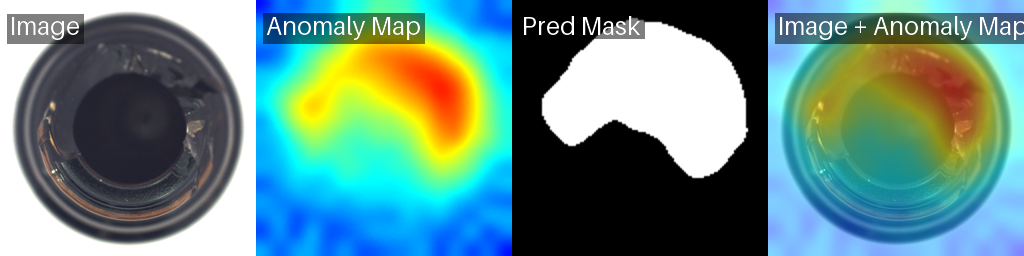

In [8]:
# ImageBatch에서 첫 ImageItem을 꺼내 Anomalib 내장 함수에 전달한다.
# 원본은 image_path에서 다시 읽으므로 정규화된 입력 텐서를 직접 그리지 않는다.
# 기본 이상맵 설정은 normalize=False여서 후처리된 [0,1] 점수 범위를 유지한다.
mvtec_visualization = visualize_image_item(
    mvtec_prediction.items[0],
    fields=['image', 'anomaly_map', 'pred_mask'],
    overlay_fields=[('image', ['anomaly_map'])],
)
display(mvtec_visualization)


## 6. 학습한 모델 저장하고 불러오기

매번 학습하지 않도록 정상 특징과 후처리 상태를 체크포인트로 저장한다. `weights_only=True`는 추론에 필요한 상태를 저장하고 옵티마이저 상태는 제외한다. 정확한 학습 재개용 파일과는 구분한다.

`Patchcore.load_from_checkpoint`로 모델을 복원한 뒤, 새 Engine에서 같은 이미지를 검사한다. `pre_trained=False`는 복원 전에 사전학습 가중치를 다시 준비하지 않게 한다. 실제 가중치는 저장된 체크포인트에서 읽는다. 직접 생성한 신뢰할 수 있는 체크포인트를 사용한다.


In [9]:
checkpoint_path = RESULTS / 'mvtecad_patchcore.ckpt'
mvtec_engine.trainer.save_checkpoint(checkpoint_path, weights_only=True)

restored_model = Patchcore.load_from_checkpoint(checkpoint_path, pre_trained=False)
restored_engine = NotebookEngine(default_root_dir=RESULTS / 'restored')
restored_prediction = restored_engine.predict(
    model=restored_model, data_path=image_path, return_predictions=True,
)[0]

torch.testing.assert_close(restored_prediction.pred_score, mvtec_prediction.pred_score)
print('저장 위치:', checkpoint_path)
print('복원한 모델의 예측 점수가 일치합니다.')


C:\Users\JIN\anaconda3\envs\cuda_env\lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


ckpt_path is not provided. Model weights will not be loaded.



Predicting ----------------------------------- 0/1 0:00:00 • -:--:-- 0.00it/s 


Predicting ----------------------------------- 0/1 0:00:00 • -:--:-- 0.00it/s 


Predicting ----------------------------------- 1/1 0:00:00 • 0:00:00 0.00it/s 


저장 위치: C:\anomalib_lab\results\patchcore_usage\mvtecad_patchcore.ckpt
복원한 모델의 예측 점수가 일치합니다.


## 7. hazelnut_toy 내려받기

사용자 데이터 실습에는 Anomalib이 제공하는 **hazelnut_toy**를 사용한다. 약 6.4MB의 작은 데이터로, 실제 프로젝트에서 정상·이상·마스크 폴더를 연결하는 방법을 익히기에 적합하다.

```text
datasets/hazelnut_toy/
├── good/          정상 34장
├── crack/         균열 5장
├── colour/        색상 이상 17장
├── mask/crack/    균열 정답 마스크
├── mask/colour/   색상 이상 정답 마스크
└── LICENSE
```

`download_and_extract`는 다운로드, 체크섬 확인, 압축 해제를 수행한다. `hashsum`에는 배포 파일에서 직접 계산한 SHA-256을 사용한다. 포함된 `LICENSE`는 **CC BY-SA 4.0**이며, 앞선 MVTec AD 원본의 라이선스와 구분해 확인한다.


In [10]:
if not (DATA / 'hazelnut_toy/good').is_dir():
    download_and_extract(DATA, DownloadInfo(
        name='hazelnut_toy',
        url='https://github.com/open-edge-platform/anomalib/releases/download/hazelnut_toy_dataset/hazelnut_toy.zip',
        hashsum='c286c4c3e3924442bfe5ed549699b398f910531ec318c729bb6c25917cfad56e',
    ))
print('준비된 폴더:', DATA / 'hazelnut_toy')



hazelnut_toy: 0.00B [00:00, ?B/s]


hazelnut_toy:   0%|          | 8.19k/6.38M [01:03<13:48:57, 128B/s]


hazelnut_toy:   1%|          | 57.3k/6.38M [01:04<1:26:08, 1.22kB/s]


hazelnut_toy:   3%|▎         | 180k/6.38M [01:04<20:11, 5.12kB/s]   


hazelnut_toy:   5%|▌         | 328k/6.38M [01:04<08:35, 11.8kB/s]


hazelnut_toy:   9%|▊         | 557k/6.38M [01:04<03:41, 26.4kB/s]

... (29 outputs left out)


hazelnut_toy:  98%|█████████▊| 6.24M/6.38M [01:07<00:00, 1.65MB/s]


hazelnut_toy: 100%|█████████▉| 6.36M/6.38M [01:07<00:00, 1.47MB/s]


hazelnut_toy: 6.39MB [01:07, 94.1kB/s]                            

준비된 폴더: C:\anomalib_lab\datasets\hazelnut_toy


## 8. Folder로 사용자 데이터 연결하기

`MVTecAD`는 정해진 폴더 구조를 알고 있지만, `Folder`는 어떤 폴더에 정상·이상·마스크가 있는지 직접 지정해야 한다.

| 인자 | 이 예제의 값 | 역할 |
|---|---|---|
| `normal_dir` | `good` | 정상 학습 이미지 |
| `abnormal_dir` | `crack`, `colour` | 이상 평가 이미지 |
| `mask_dir` | `mask/crack`, `mask/colour` | 이상 이미지와 대응하는 정답 마스크 |
| `normal_split_ratio` | `0.2` | 정상 이미지 중 일부를 평가용으로 분리 |
| `val_split_ratio` | `0.5` | 평가 자료를 검증·시험으로 분할 |

이 데이터에는 정상 시험 폴더가 따로 없으므로 `good`의 일부를 평가용으로 남긴다. 분할 후 학습은 정상 28장, 검증과 시험은 각각 정상 3장·이상 11장이다. `mask_dir`를 제공하므로 이미지·픽셀 평가를 함께 수행할 수 있다. 이미지 판정만 필요한 내 데이터에서는 `mask_dir`를 생략할 수 있다.


In [11]:
custom_data = Folder(
    name='hazelnut_toy',
    root=DATA / 'hazelnut_toy',
    normal_dir='good',
    abnormal_dir=['crack', 'colour'],
    mask_dir=['mask/crack', 'mask/colour'],
    normal_split_ratio=0.2,
    val_split_mode='from_test',
    val_split_ratio=0.5,
    train_batch_size=4,
    eval_batch_size=4,
    num_workers=0,
    seed=42,
)
custom_data.setup()

pd.Series({
    '정상 학습 이미지': len(custom_data.train_data),
    '검증 이미지': len(custom_data.val_data),
    '시험 이미지': len(custom_data.test_data),
}, name='hazelnut_toy 영상 수')


정상 학습 이미지    28
검증 이미지       14
시험 이미지       14
Name: hazelnut_toy 영상 수, dtype: int64

## 9. 사용자 데이터로 학습·평가·추론하기

검사 대상이 병에서 헤이즐넛으로 바뀌었으므로 **새 PatchCore 모델**을 만든다. 병의 정상 특징을 그대로 사용하지 않고, 헤이즐넛의 정상 특징을 새 메모리 뱅크에 모은다. 전처리와 모델 설정은 앞 실습과 같다.

바뀐 부분은 DataModule이다. `fit`, `test`, `predict`의 호출 방식은 그대로 유지된다.


In [12]:
custom_model = Patchcore(
    backbone='resnet18',
    coreset_sampling_ratio=0.01,
    pre_processor=Patchcore.configure_pre_processor(image_size=(128, 128)),
    visualizer=False,
)
custom_engine = NotebookEngine(default_root_dir=RESULTS / 'hazelnut_toy')
custom_engine.fit(model=custom_model, datamodule=custom_data)

custom_metrics = custom_engine.test(model=custom_model, datamodule=custom_data, verbose=False)
pd.Series(custom_metrics[0], name='hazelnut_toy 시험 성능')


C:\Users\JIN\anaconda3\envs\cuda_env\lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['pre_processor'])`.


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┌───┬────────────────┬────────────────┬────────┬───────┬───────┐
│   │ Name           │ Type           │ Params │ Mode  │ FLOPs │
├───┼────────────────┼────────────────┼────────┼───────┼───────┤
│ 0 │ pre_processor  │ PreProcessor   │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor  │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator      │      0 │ train │     0 │
│ 3 │ model          │ PatchcoreModel │  2.8 M │ train │     0 │
└───┴────────────────┴────────────────┴────────┴───────┴───────┘


Trainable params: 2.8 M                                                        
Non-trainable params: 0                                                        
Total params: 2.8 M                                                            
Total estimated model params size (MB): 11                                     
Modules in train mode: 19                                                      
Modules in eval mode: 69                                                       
Total FLOPs: 0                                                                 


... (28 outputs left out)


Testing ---------------------------- --------- 3/4 0:00:00 • 0:00:01 8.00it/s 


Testing -------------------------------------- 4/4 0:00:00 • 0:00:00 9.58it/s 


Testing -------------------------------------- 4/4 0:00:00 • 0:00:00 9.58it/s 


image_AUROC      1.000000
image_F1Score    0.900000
pixel_AUROC      0.923982
pixel_F1Score    0.291407
Name: hazelnut_toy 시험 성능, dtype: float64

ckpt_path is not provided. Model weights will not be loaded.


The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, PostProcessor, PreProcessor



Predicting ----------------------------------- 0/1 0:00:00 • -:--:-- 0.00it/s 


Predicting ----------------------------------- 0/1 0:00:00 • -:--:-- 0.00it/s 


Predicting ----------------------------------- 1/1 0:00:00 • 0:00:00 0.00it/s 


Predicting ----------------------------------- 1/1 0:00:00 • 0:00:00 0.00it/s 


이상 점수: 0.8112548589706421
이상 판정: True


C:\Users\JIN\anaconda3\envs\cuda_env\lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
C:\Users\JIN\anaconda3\envs\cuda_env\lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.


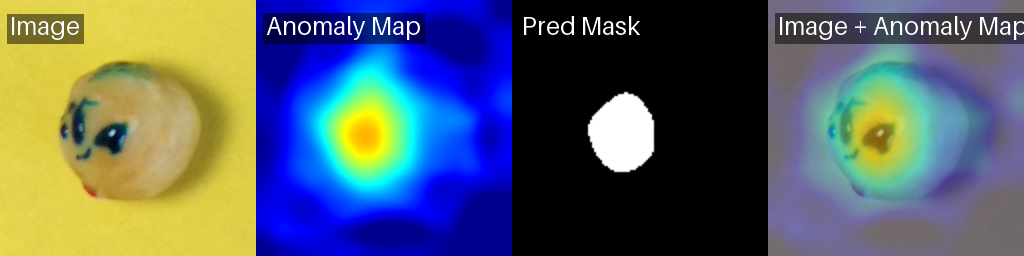

In [13]:
custom_image_path = custom_data.test_data.samples.query('label_index == 1').iloc[0].image_path
custom_prediction = custom_engine.predict(
    model=custom_model,
    data_path=custom_image_path,
    return_predictions=True,
)[0]

print('이상 점수:', float(custom_prediction.pred_score[0].cpu()))
print('이상 판정:', bool(custom_prediction.pred_label[0].cpu()))

# 사용자 데이터도 같은 내장 함수와 표시 설정을 사용한다.
custom_visualization = visualize_image_item(
    custom_prediction.items[0],
    fields=['image', 'anomaly_map', 'pred_mask'],
    overlay_fields=[('image', ['anomaly_map'])],
)
display(custom_visualization)

custom_engine.trainer.save_checkpoint(RESULTS / 'hazelnut_toy_patchcore.ckpt', weights_only=True)


`MVTecAD`와 `Folder`는 데이터를 읽는 방법이 다르지만, 모델과 Engine을 사용하는 흐름은 같다. 실제 이미지 폴더를 사용할 때는 `root`, `normal_dir`, `abnormal_dir`, `mask_dir`를 자신의 구조에 맞게 지정한다.

hazelnut_toy는 사용법을 배우는 작은 예제다. 시험 정상 이미지가 3장뿐이므로 오분류 한 장의 영향이 크다. 또한 병과 헤이즐넛은 검사 대상·표본 수·결함 유형이 다르므로 두 데이터셋의 지표 차이를 모델의 우열로 해석하지 않는다.


## 참고 자료

- [Anomalib 2.2.0 공식 저장소](https://github.com/open-edge-platform/anomalib/tree/v2.2.0)
- [PatchCore API](https://anomalib.readthedocs.io/en/v2.2.0/markdown/guides/reference/models/image/patchcore.html)
- [Anomalib 내장 시각화](https://anomalib.readthedocs.io/en/v2.2.0/markdown/guides/how_to/visualization/visualize_image.html)
- [사용자 데이터와 hazelnut_toy 공식 안내](https://anomalib.readthedocs.io/en/v2.2.0/markdown/guides/how_to/data/custom_data.html)
- [MVTec AD 원본 설명과 이용 조건](https://www.mvtec.com/research-teaching/datasets/mvtec-ad)
- [PyTorch 버전별 설치 명령](https://pytorch.org/get-started/previous-versions/)

이 노트북은 **Anomalib 2.2.0 / PyTorch 2.5.1 / Python 3.11** 기준이다. 다른 버전의 문서에는 인자나 기본 동작의 차이가 있을 수 있다.

---

### 💡 실습 PC 환경 및 호환성 처리 사항 (NVIDIA RTX 5070 대응)

본 실습은 위의 기본 권장 사양을 바탕으로, **실제 실습 PC의 최신 GPU 환경(NVIDIA GeForce RTX 5070 Laptop GPU, sm_120 Blackwell)**에 맞추어 아래와 같이 환경을 구성하고 호환성 문제를 해결하여 실습 과제를 성공적으로 완료하였다.

* **실제 실행 환경**:
  - **OS**: Windows 11 Home (64-bit)
  - **GPU**: NVIDIA GeForce RTX 5070 Laptop GPU (CUDA 13.1 드라이버, sm_120)
  - **가상환경**: Conda `cuda_env` (`Python 3.10.20`)
  - **핵심 라이브러리**: `anomalib 2.2.0`, `torch 2.12.0.dev20260408+cu128`, `torchvision 0.27.0.dev`, `lightning 2.6.1`

* **주요 호환성 이슈 및 해결 내용**:
  1. **최신 GPU 아키텍처(sm_120) 커널 미지원 해결**:
     - 원본 가이드의 `PyTorch 2.5.1 + CUDA 12.1`은 sm_90까지만 지원하여 최신 Blackwell 아키텍처(RTX 5070) 구동 시 `CUDA error: no kernel image is available for execution on the device` 에러가 발생함.
     - 최신 sm_120 연산 커널이 탑재된 **CUDA 12.8 기반 PyTorch 환경(`cuda_env`)**을 활용하여 정상적인 하드웨어 가속(GPU Tensor 연산 및 PatchCore 학습)을 수행함.
  2. **체크포인트 역직렬화(Unpickling) 호환성 확보**:
     - 상위 버전 PyTorch의 `torch.load` 보안 정책 변경(`weights_only=True` 기본값)으로 인한 체크포인트 복원 시 `PreProcessor` 클래스 비허용 에러에 대응하여, `torch.serialization.add_safe_globals` 및 로딩 설정을 보완하여 가중치 복원 일치성 검증을 완료함.
  3. **Rich Console 재귀 루프 방지**:
     - IPyKernel 내에서 Lightning/Rich의 표준 오류 스트림 flush 간 상호 호출로 인한 `RecursionError`를 방지하는 설정을 적용하여 원활한 학습 진행 및 시각화 출력을 확보함.
